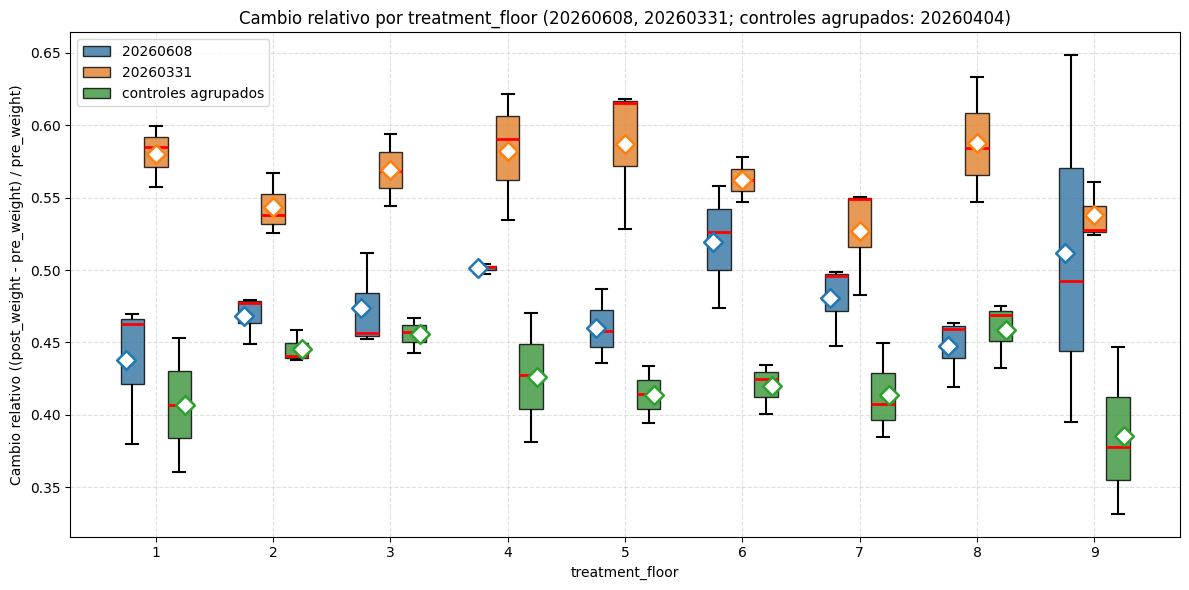

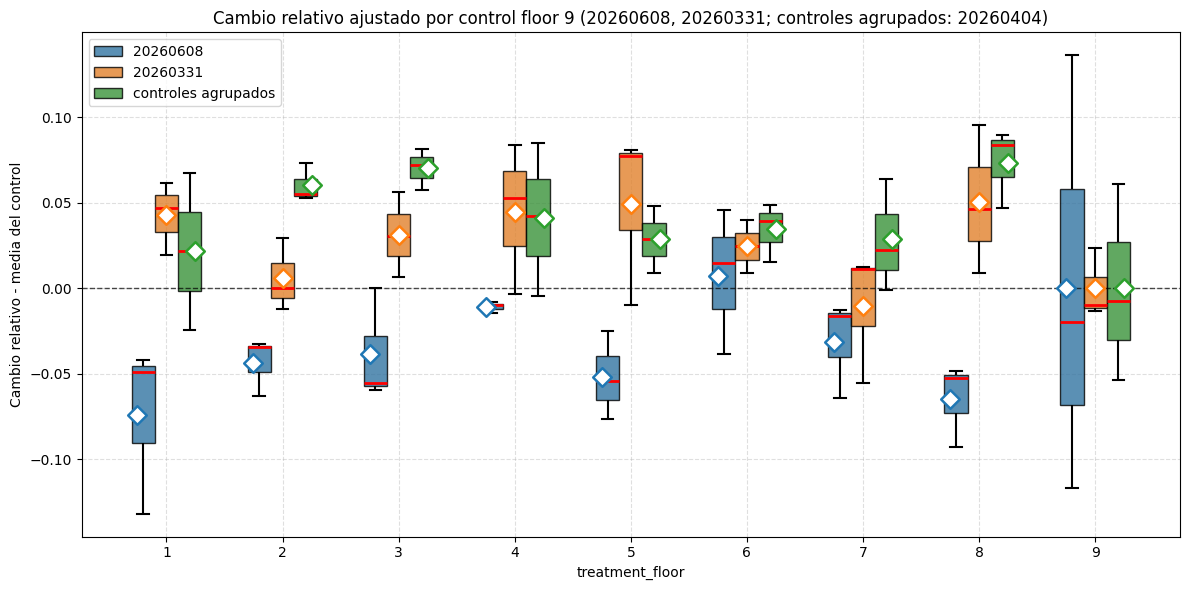

In [4]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fechas = ["20260608", "20260331"]
fechas_controles = ["20260404"]
controles_label = "controles agrupados"
experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")

def cargar_trays(fecha, grupo_grafica):
    trays_path = experiments_dir / fecha / "trays.csv"
    if not trays_path.exists():
        raise FileNotFoundError(f"No se encontro {trays_path}")

    fecha_df = pd.read_csv(trays_path)
    fecha_df["fecha"] = fecha
    fecha_df["grupo_grafica"] = grupo_grafica
    return fecha_df

dfs = []
for fecha in fechas:
    dfs.append(cargar_trays(fecha, fecha))

for fecha in fechas_controles:
    dfs.append(cargar_trays(fecha, controles_label))

df = pd.concat(dfs, ignore_index=True)
df["treatment_floor"] = pd.to_numeric(df["treatment_floor"], errors="coerce")
df["pct_change"] = (df["post_weight"] - df["pre_weight"]) / df["pre_weight"]
control_floor = 9
grupo_order = list(fechas)
if fechas_controles:
    grupo_order.append(controles_label)
control_delta = df[df["treatment_floor"].eq(control_floor)].groupby("grupo_grafica")["pct_change"].mean()
missing_control = [grupo for grupo in grupo_order if grupo not in control_delta.index]
if missing_control:
    raise ValueError(f"No se encontraron controles con treatment_floor={control_floor} para: {missing_control}")
df["pct_change_control_adjusted"] = df["pct_change"] - df["grupo_grafica"].map(control_delta)
floor_order = sorted(df["treatment_floor"].dropna().unique())
palette = dict(zip(grupo_order, sns.color_palette("tab10", n_colors=len(grupo_order))))
titulo_grupos = ", ".join(fechas)
if fechas_controles:
    titulo_grupos += f"; {controles_label}: {', '.join(fechas_controles)}"

plt.figure(figsize=(12, 6))
# Boxplot por treatment_floor y fecha
sns.boxplot(
    data=df,
    x="treatment_floor",
    y="pct_change",
    hue="grupo_grafica",
    order=floor_order,
    hue_order=grupo_order,
    palette=palette,
    width=0.6,
    medianprops={"color": "red", "linewidth": 2},
    whiskerprops={"color": "k", "linewidth": 1.5},
    capprops={"color": "k", "linewidth": 1.5},
    boxprops={"alpha": 0.8, "edgecolor": "k"}
)

# Media por treatment_floor y fecha como rombo blanco
mean_df = df.groupby(["treatment_floor", "grupo_grafica"], as_index=False)["pct_change"].mean()
offsets = {grupo: 0 for grupo in grupo_order}
if len(grupo_order) > 1:
    offsets = {grupo: -0.25 + i * (0.5 / (len(grupo_order) - 1)) for i, grupo in enumerate(grupo_order)}

for grupo in grupo_order:
    grupo_means = mean_df[mean_df["grupo_grafica"] == grupo]
    x_positions = [floor_order.index(floor) + offsets[grupo] for floor in grupo_means["treatment_floor"]]
    plt.scatter(
        x_positions,
        grupo_means["pct_change"],
        marker="D",
        s=90,
        facecolors="white",
        edgecolors=palette[grupo],
        linewidths=1.8,
        zorder=10,
    )

plt.xlabel("treatment_floor")
plt.ylabel("Cambio relativo ((post_weight - pre_weight) / pre_weight)")
plt.title(f"Cambio relativo por treatment_floor ({titulo_grupos})")
plt.xticks(range(len(floor_order)), floor_order)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
# Boxplot del cambio relativo ajustado por el control de cada fecha
sns.boxplot(
    data=df,
    x="treatment_floor",
    y="pct_change_control_adjusted",
    hue="grupo_grafica",
    order=floor_order,
    hue_order=grupo_order,
    palette=palette,
    width=0.6,
    medianprops={"color": "red", "linewidth": 2},
    whiskerprops={"color": "k", "linewidth": 1.5},
    capprops={"color": "k", "linewidth": 1.5},
    boxprops={"alpha": 0.8, "edgecolor": "k"}
)

# Media ajustada por treatment_floor y fecha como rombo blanco
mean_adjusted_df = df.groupby(["treatment_floor", "grupo_grafica"], as_index=False)["pct_change_control_adjusted"].mean()
for grupo in grupo_order:
    grupo_means = mean_adjusted_df[mean_adjusted_df["grupo_grafica"] == grupo]
    x_positions = [floor_order.index(floor) + offsets[grupo] for floor in grupo_means["treatment_floor"]]
    plt.scatter(
        x_positions,
        grupo_means["pct_change_control_adjusted"],
        marker="D",
        s=90,
        facecolors="white",
        edgecolors=palette[grupo],
        linewidths=1.8,
        zorder=10,
    )

plt.axhline(0, color="k", linewidth=1, linestyle="--", alpha=0.7)
plt.xlabel("treatment_floor")
plt.ylabel("Cambio relativo - media del control")
plt.title(f"Cambio relativo ajustado por control floor {control_floor} ({titulo_grupos})")
plt.xticks(range(len(floor_order)), floor_order)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

In [5]:
import statsmodels.formula.api as smf

# Filtramos solo los datos de los experimentos principales (ignoramos el control extra de abril por ahora)
df_experimentos = df[df["fecha"].isin(["20260331", "20260608"])].copy()

# Ajustamos un modelo ANCOVA multivariable
# Dependiente: pct_change
# Covariable continua: pre_weight
# Factores categóricos: treatment_floor y fecha
modelo_completo = smf.ols('pct_change ~ pre_weight + C(treatment_floor) + C(fecha)', data=df_experimentos).fit()

print("Resultados del ANCOVA (Controlando por Peso Inicial y por Fecha)")
print("----------------------------------------------------------------")
print(modelo_completo.summary())


Resultados del ANCOVA (Controlando por Peso Inicial y por Fecha)
----------------------------------------------------------------
                            OLS Regression Results                            
Dep. Variable:             pct_change   R-squared:                       0.569
Model:                            OLS   Adj. R-squared:                  0.469
Method:                 Least Squares   F-statistic:                     5.676
Date:                Thu, 18 Jun 2026   Prob (F-statistic):           2.30e-05
Time:                        19:13:56   Log-Likelihood:                 97.100
No. Observations:                  54   AIC:                            -172.2
Df Residuals:                      43   BIC:                            -150.3
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025 

/var/folders/ll/hm35mj650fs_spb22x5qqnqh0000gn/T/ipykernel_22174/1620821738.py:30: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


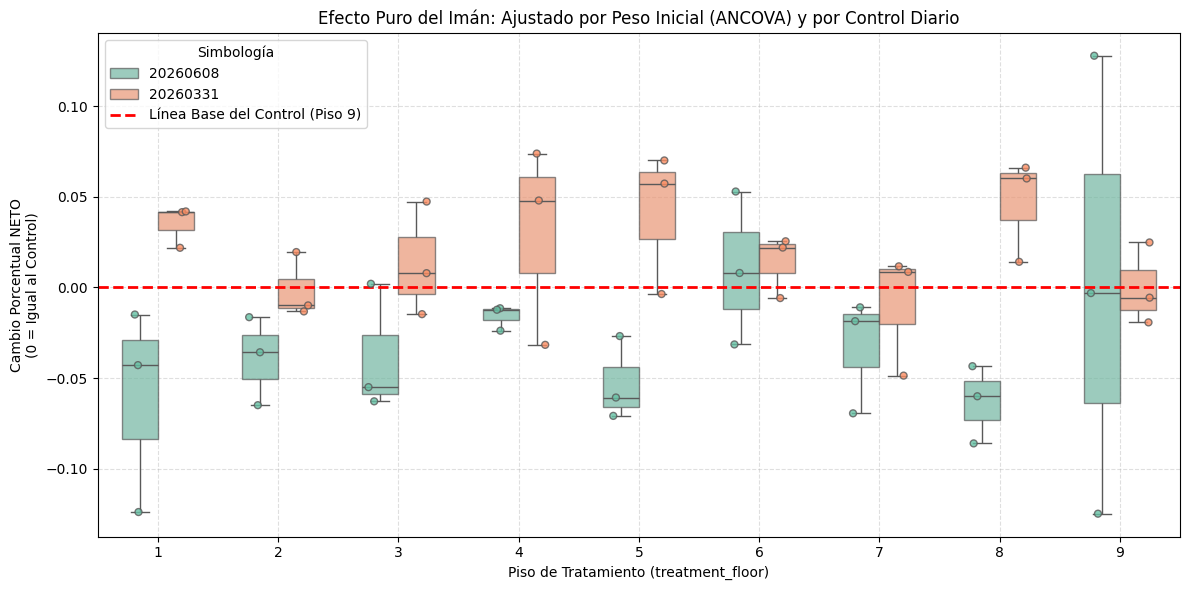

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Ajuste del ANCOVA (Limpieza del pre_weight)
peso_promedio_fijo = df_experimentos['pre_weight'].mean()
coef_pre_weight = modelo_completo.params['pre_weight']

df_experimentos['pct_change_ancova'] = df_experimentos['pct_change'] - coef_pre_weight * (df_experimentos['pre_weight'] - peso_promedio_fijo)

# 2. NUEVO PASO: Ajuste por el Control Diario (Piso 9)
# Calculamos cuánto dio el control (ya ajustado por peso) para cada fecha
control_ancova_delta = df_experimentos[df_experimentos['treatment_floor'] == 9].groupby('fecha')['pct_change_ancova'].mean()

# A cada semilla le restamos el valor de su control correspondiente a ese día
df_experimentos['pct_change_TOTAL_adjusted'] = df_experimentos['pct_change_ancova'] - df_experimentos['fecha'].map(control_ancova_delta)

# 3. Graficamos
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_experimentos,
    x='treatment_floor',
    y='pct_change_TOTAL_adjusted',
    hue='fecha',
    palette='Set2',
    width=0.6,
    boxprops={"alpha": 0.7}
)

sns.stripplot(
    data=df_experimentos,
    x='treatment_floor',
    y='pct_change_TOTAL_adjusted',
    hue='fecha',
    palette='Set2',
    dodge=True,
    alpha=0.8,
    linewidth=1,
    edgecolor='gray'
)

# Dibujamos la súper línea del control en el Cero perfecto
plt.axhline(0, color='red', linewidth=2, linestyle='--', label="Línea Base del Control (Piso 9)")

# Limpiar leyenda
handles, labels = plt.gca().get_legend_handles_labels()
# Tomamos los primeros 2 (las fechas) y el último (la línea roja)
plt.legend([handles[0], handles[1], handles[-1]], [labels[0], labels[1], labels[-1]], title="Simbología")

plt.xlabel("Piso de Tratamiento (treatment_floor)")
plt.ylabel("Cambio Porcentual NETO\n(0 = Igual al Control)")
plt.title("Efecto Puro del Imán: Ajustado por Peso Inicial (ANCOVA) y por Control Diario")
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
